<a href="https://colab.research.google.com/github/aeron-j/Dale-csc173-repository/blob/main/flood_vit_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install -U keras-hub
import tensorflow as tf, keras, keras_hub
print('GPU:', tf.config.list_physical_devices('GPU'))

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-nlp 0.26.0 requires keras-hub==0.26.0, but you have keras-hub 0.33.0 which is incompatible.
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from pathlib import Path

DATA_DIR = Path('/content/drive/MyDrive/Sorted_Dataset')
CLASSES = ['clear', 'passable', 'impassable']
IMG_EXT = {'.jpg', '.jpeg', '.png', '.webp'}

for c in CLASSES:
    files = [p for p in (DATA_DIR / c).glob('*') if p.suffix.lower() in IMG_EXT]
    print(c, len(files))

clear 111
passable 115
impassable 326


## **Step 4: Inspect Data then Split**

clear | sample names: ['clean_1.jpg', 'clean_100.jpg', 'clean_101.jpg', 'clean_102.jpg']
   median size: 956 x 614
passable | sample names: ['image_1.jpg', 'image_116.jpg', 'image_122.jpg', 'image_130.jpg']
   median size: 512 x 384
impassable | sample names: ['image_10.jpg', 'image_100.jpg', 'image_101.jpg', 'image_102.jpg']
   median size: 512 x 384


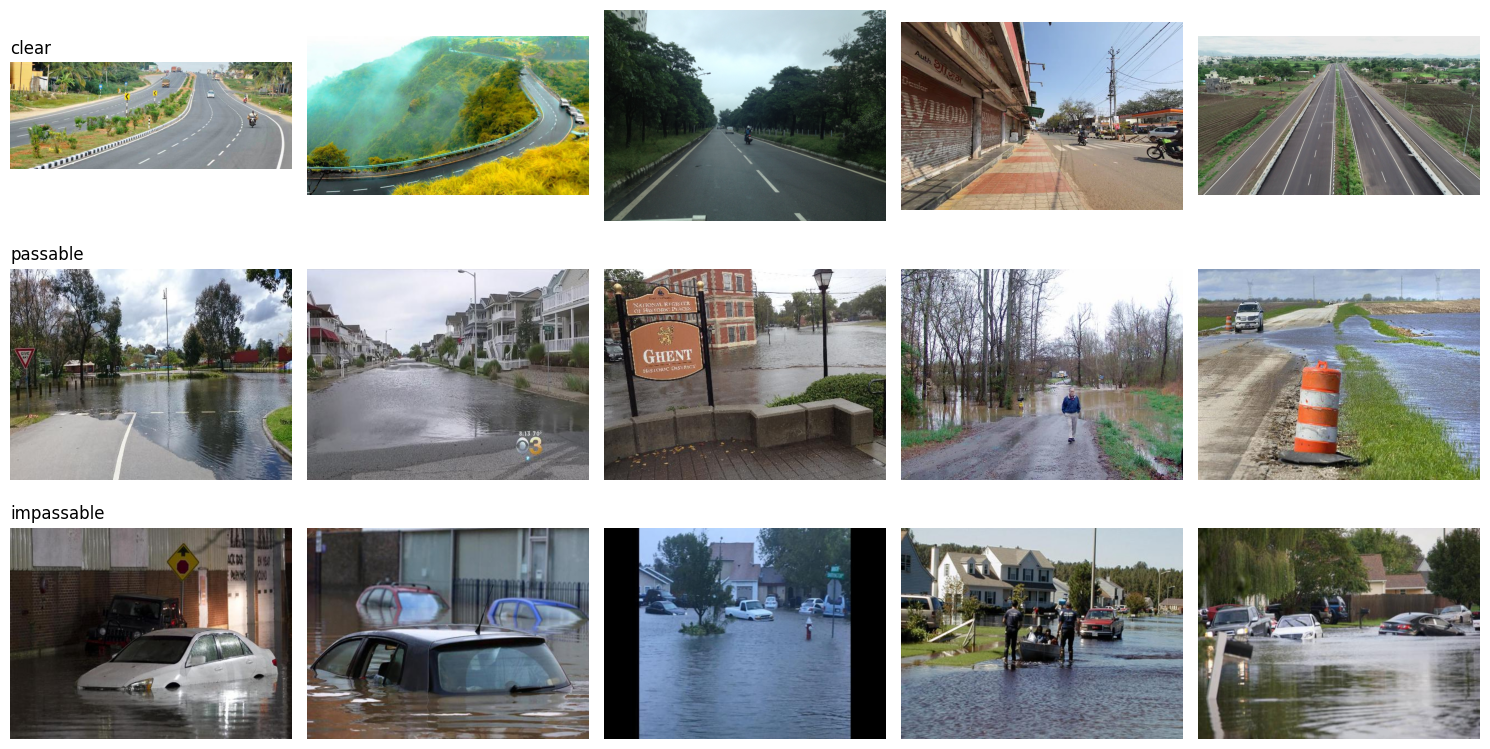

In [4]:
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

random.seed(0)
for c in CLASSES:
    files = [p for p in (DATA_DIR / c).glob('*') if p.suffix.lower() in IMG_EXT]
    print(c, '| sample names:', sorted(p.name for p in files)[:4])
    sizes = [Image.open(p).size for p in random.sample(files, min(30, len(files)))]
    print(f"   median size: {np.median([s[0] for s in sizes]):.0f} x {np.median([s[1] for s in sizes]):.0f}")

fig, axes = plt.subplots(3, 5, figsize=(15, 8))
for r, c in enumerate(CLASSES):
    files = [p for p in (DATA_DIR / c).glob('*') if p.suffix.lower() in IMG_EXT]
    for ax, p in zip(axes[r], random.sample(files, 5)):
        ax.imshow(Image.open(p).convert('RGB')); ax.axis('off')
    axes[r][0].set_title(c, loc='left')
plt.tight_layout(); plt.show()

In [5]:
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
rows = []
for label, c in enumerate(CLASSES):
    for p in sorted((DATA_DIR / c).glob('*')):
        if p.suffix.lower() in IMG_EXT:
            rows.append(dict(path=str(p), name=p.name, label=label, cls=c))
df = pd.DataFrame(rows)

def get_group(name):
    stem = name.rsplit('.', 1)[0]
    return stem.split('__')[0] if '__' in stem else stem   # edit this if your filenames use another pattern

df['group'] = df.name.map(get_group)
print(df.group.nunique(), 'source groups for', len(df), 'images')

df['split'] = 'train'
sg = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
tv_idx, te_idx = next(sg.split(df, df.label, df.group))
df.loc[te_idx, 'split'] = 'test'
tv = df.loc[tv_idx]
sg2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
_, va_idx = next(sg2.split(tv, tv.label, tv.group))
df.loc[tv.index[va_idx], 'split'] = 'val'

g = {s: set(df[df.split == s].group) for s in ['train', 'val', 'test']}
assert not (g['train'] & g['val']) and not (g['train'] & g['test']) and not (g['val'] & g['test'])

OUT_DIR = Path('/content/drive/MyDrive/flood_project'); OUT_DIR.mkdir(exist_ok=True)
df[['name', 'cls', 'group', 'split']].to_csv(OUT_DIR / 'splits.csv', index=False)
print(pd.crosstab(df.split, df.cls).reindex(index=['train', 'val', 'test'], columns=CLASSES))

552 source groups for 552 images
cls    clear  passable  impassable
split                             
train     78        84         232
val       16        15          48
test      17        16          46
